# 2 · Eddy-covariance reference flux

Turbulent eddies transport heat upward when rising air ($w' > 0$) is on average warmer ($\theta' > 0$) than
sinking air. The sensible heat flux is this covariance multiplied by the heat capacity of air:

$$H_\mathrm{S} = \rho\, c_p\, \overline{w'\theta'}$$

This chapter derives the flux of one 5 km segment from the 100 Hz data and reproduces the value stored for it in the
segment file `data/observations/ar/analysis_ready_polar6_turbulent_fluxes_latest_5km.nc`. That file holds one row per
5 km segment (EC flux, random error, integrity check and segment means) and is written by
`scripts/run_ec_aggregation.py`; its variables are listed under [Data files](../docs/data.md).

> [!NOTE]
> **Paper:** Sect. 3.1, Eq. (1), Fig. 3, Appendix A. **Code:** `fluxpy/eddy_covariance.py`
> (`band_covariance`, `band_covariance_random_error`, `segment_flux`), `fluxpy/qc.py` (integrity check),
> `scripts/ec_window_length.py` (Fig. 3), `scripts/ec_quality.py` (every number of Appendix A).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 90 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

from fluxpy.eddy_covariance import band_covariance, segment_flux
from fluxpy.util import CP, RD, add_theta

TB = xr.open_dataset(REPO / "data/observations/processed/t-bird_unified/noseboom_unified.nc").sortby("time")
i = int(np.nanargmax(EC))                                   # the segment with the largest upward flux
t0, t1 = SEG.start_time.values[i], SEG.end_time.values[i]
seg = add_theta(TB.sel(time=slice(t0, t1))).dropna("time", how="any")
print(f"segment {pd.Timestamp(t0):%d %b %Y %H:%M:%S} UTC: {seg.time.size} samples = {seg.time.size / 100:.0f} s at 100 Hz, "
      f"height {float(seg.h.mean()):.0f} m, airspeed {float(seg.tas.mean()):.0f} m/s")

segment 15 Apr 2024 10:18:10 UTC: 8500 samples = 85 s at 100 Hz, height 25 m, airspeed 58 m/s


## Detrended time series

Vertical wind $w$ and potential temperature $\theta$ are measured at 100 Hz. The platform motion has been removed from the wind
with the inertial navigation data; the potential rather than the virtual potential temperature is used because the
air is cold and dry (paper Sect. 3.1). Removing a linear trend from both series yields the fluctuations $w'$ and
$\theta'$.

plain covariance of the detrended series: 0.0134 K m/s


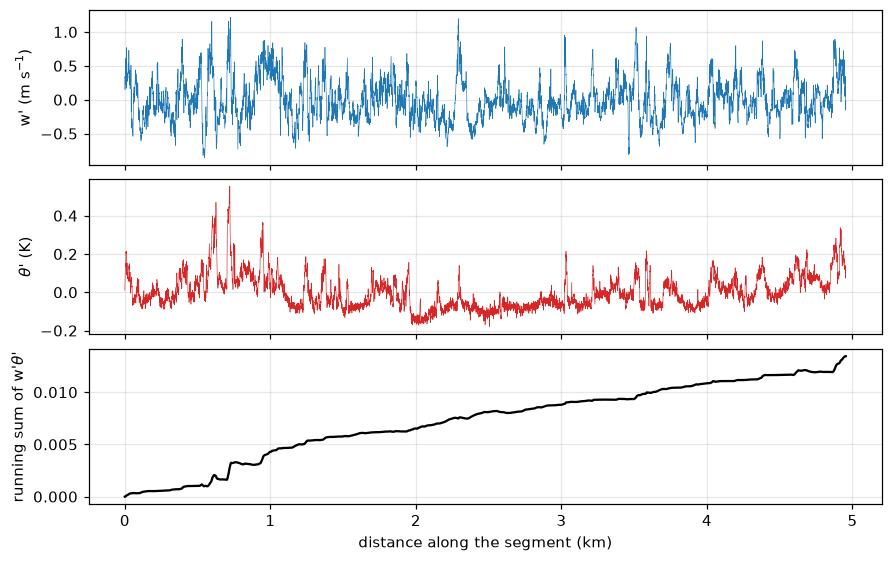

In [2]:
from scipy.signal import detrend
w, th = detrend(seg.w.values), detrend(seg.theta.values)
x_km = np.arange(w.size) / 100 * float(seg.tas.mean()) / 1000
fig, axs = plt.subplots(3, 1, figsize=(8, 5), sharex=True)
axs[0].plot(x_km, w, lw=0.4, color="C0"); axs[0].set_ylabel("w' (m s$^{-1}$)")
axs[1].plot(x_km, th, lw=0.4, color="C3"); axs[1].set_ylabel(r"$\theta$' (K)")
axs[2].plot(x_km, np.cumsum(w * th) / w.size, color="k"); axs[2].set_ylabel(r"running sum of w'$\theta$'"); axs[2].set_xlabel("distance along the segment (km)")
print(f"plain covariance of the detrended series: {np.mean(w * th):.4f} K m/s")

**Figure 2.1.** Detrended vertical wind $w'$ (top) and potential temperature $\theta'$ (middle) along the segment, and
the running sum of $w'\theta'$ divided by the number of samples (bottom), which ends at the covariance of the segment.

## Cospectrum and flux band

The cospectrum distributes the covariance over frequency. At the mean airspeed of 60 m s⁻¹, a frequency $f$
corresponds to an eddy length of $60\,\mathrm{m\,s^{-1}}/f$. The flux is the cospectrum integrated between
**0.1 and 20 Hz** (eddies of about 3 to 600 m): slower variations are attributed to mesoscale changes along the
track, faster ones to instrument noise. Only the shaded band enters the flux.

covariance inside 0.1-20 Hz: 0.0093 K m/s = 69 % of the total covariance of this segment


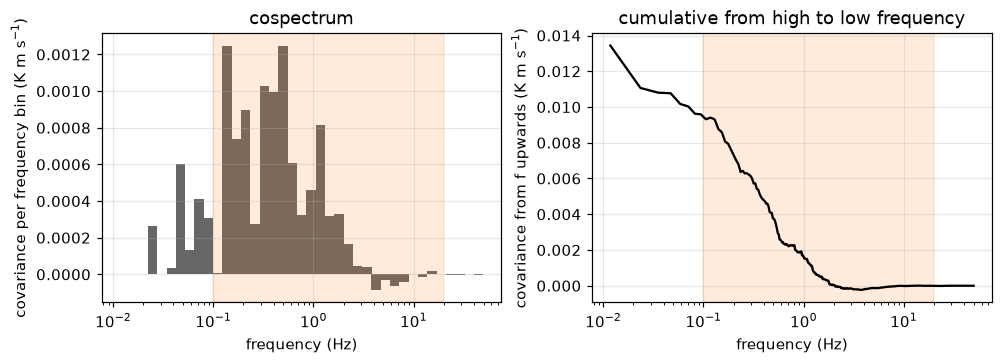

In [3]:
n, fs = w.size, 100.0
f = np.fft.rfftfreq(n, 1 / fs)
co = 2 * np.real(np.fft.rfft(w) * np.conj(np.fft.rfft(th))) / n**2       # one-sided cospectrum; sums to the covariance
edges = np.logspace(np.log10(f[1]), np.log10(50), 40); mid = np.sqrt(edges[:-1] * edges[1:])
binned = np.array([co[(f >= a) & (f < b)].sum() for a, b in zip(edges[:-1], edges[1:])])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].bar(mid, binned, width=np.diff(edges), color="0.4"); axs[0].set_xscale("log")
axs[0].set_ylabel("covariance per frequency bin (K m s$^{-1}$)"); axs[0].set_title("cospectrum")
axs[1].plot(f[1:], np.cumsum(co[1:][::-1])[::-1], color="k"); axs[1].set_xscale("log")
axs[1].set_ylabel("covariance from f upwards (K m s$^{-1}$)"); axs[1].set_title("cumulative from high to low frequency")
for ax in axs:
    ax.axvspan(0.1, 20, color="C1", alpha=0.15); ax.set_xlabel("frequency (Hz)")
in_band = band_covariance(w, th, fs, 0.1, 20.0)
print(f"covariance inside 0.1-20 Hz: {in_band:.4f} K m/s = {in_band / np.mean(w * th) * 100:.0f} % of the total covariance of this segment")

**Figure 2.2.** Left: cospectrum of $w'$ and $\theta'$, summed in logarithmically spaced frequency bins. Right:
covariance contained in all frequencies above $f$, accumulated from high to low frequency. The shaded band
(0.1–20 Hz) is the part that enters the flux.

## Conversion to W m⁻²

In [4]:
rho = float((seg.p * 100 / (RD * (seg["T"] + 273.15))).mean())        # dry-air density from p (hPa) and T (degC)
H_by_hand = rho * CP * in_band
H_fluxpy = segment_flux(seg).flux
print(f"rho = {rho:.2f} kg m-3, c_p = {CP:.0f} J kg-1 K-1")
print(f"H by hand            : {H_by_hand:6.2f} W m-2")
print(f"H from fluxpy        : {float(H_fluxpy):6.2f} W m-2")
print(f"H in the segment file: {float(SEG.sensible_heat_flux[i]):6.2f} W m-2")

rho = 1.40 kg m-3, c_p = 1004 J kg-1 K-1
H by hand            :  13.14 W m-2
H from fluxpy        :  13.14 W m-2
H in the segment file:  13.14 W m-2


## Integrity check and random error (Appendix A)

Two properties are assessed separately.

**Integrity.** Resolved turbulence shows the inertial-subrange slope in the power spectrum of $w$,
$|s_w + 5/3| \le 0.4$. The slope is reported for every segment; no segment is excluded by it. Table A1 of the paper
repeats the comparison on the segments within tolerances of 0.3 to 0.6.

**Precision.** A covariance from about 83 s of data carries a random error, because only a finite number of eddies is
sampled. It is estimated from the data (Finkelstein and Sims, 2001). For a true flux of zero, the estimate exceeds
1, 2 and 3 $\sigma_\mathrm{rand}$ by chance in 32 %, 5 % and 0.3 % of cases.

Fluxes that do not exceed their random error are **retained**. Over compact sea ice a flux indistinguishable from zero
is the typical and physically valid result; discarding such segments would bias the reference towards large fluxes. For
the same reason, criteria formulated as ratios to the flux (such as signal-to-noise ratios) are not applied: they reject
small fluxes and accept large ones irrespective of the quality of the measurement.

In [5]:
from fluxpy.qc import segment_spectra, turbulence_resolved
from fluxpy.eddy_covariance import band_covariance_random_error
slope = segment_spectra(w=seg.w.values, theta=seg.theta.values, u=seg.u.values, v=seg.v.values, fs=100.0)["slope_w"]
sigma = rho * CP * band_covariance_random_error(w, th, fs)
print(f"this segment: spectral slope of w = {slope:.2f} -> turbulence resolved: {turbulence_resolved(slope)}")
print(f"              flux {float(H_fluxpy):.1f} W m-2, random error {sigma:.2f} W m-2 -> {abs(float(H_fluxpy)) / sigma:.0f} sigma")
ratio = FIG.ec_flux_over_sigma.values
print(f"\nall {ratio.size} segments: {int(SEG.turbulence_resolved.sum())} satisfy the integrity check (none is excluded); "
      f"median random error {np.median(FIG.sigma_random_ec.values):.2f} W m-2")
days = pd.to_datetime(FIG.start_time.values).strftime("%d %b")
pd.DataFrame({f"|H| > {k} sigma": {**{d: f"{(ratio[days == d] > k).sum()} / {(days == d).sum()}" for d in pd.unique(days)},
                                   "all": f"{(ratio > k).sum()} / {ratio.size}"} for k in (1, 2, 3)})

this segment: spectral slope of w = -1.55 -> turbulence resolved: True
              flux 13.1 W m-2, random error 2.00 W m-2 -> 7 sigma

all 90 segments: 90 satisfy the integrity check (none is excluded); median random error 0.75 W m-2


,|H| > 1 sigma,|H| > 2 sigma,|H| > 3 sigma
13 Apr,13 / 17,8 / 17,7 / 17
15 Apr,22 / 22,22 / 22,22 / 22
17 Apr,16 / 26,13 / 26,4 / 26
23 Apr,16 / 25,3 / 25,0 / 25
all,67 / 90,46 / 90,33 / 90


On 15 April, the day with open leads and the largest fluxes, all fluxes clearly exceed their random error; on the days
over compact ice or with weak temperature contrast, most fluxes are statistically indistinguishable from zero. This is a
property of the surface, not a defect of the data, and it limits the correlation attainable by any estimate (Chapter 4).

## Segment length (Fig. 3)

Short windows under-sample the larger eddies; long windows average over leads and ice. Each of the six low-level legs
is cut into sub-windows of different length, and their mean flux is compared with the flux of the complete leg
(`scripts/ec_window_length.py`).

at 5 km: flux ratio 1.02, random error 0.79 W m-2, fluxes above 2 sigma 48 %


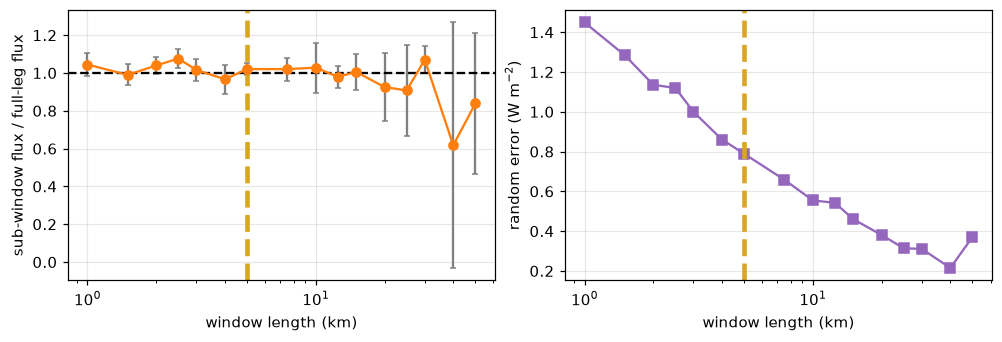

In [6]:
wl = pd.read_csv(AR / "ec_leg_length_sensitivity/ec_sensitivity_summary.csv").query("length_km >= 1 and label != 'full leg'")
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].errorbar(wl.length_km, wl.ratio_mean, wl.ratio_std, fmt="o-", color="C1", ecolor="0.5", capsize=2)
axs[0].axhline(1, color="k", ls="--"); axs[0].set_ylabel("sub-window flux / full-leg flux")
axs[1].plot(wl.length_km, wl.random_error_median, "s-", color="C4"); axs[1].set_ylabel("random error (W m$^{-2}$)")
for ax in axs:
    ax.set_xscale("log"); ax.axvline(5, color="goldenrod", lw=3, ls="--"); ax.set_xlabel("window length (km)")
r5 = wl[wl.length_km == 5].iloc[0]
print(f"at 5 km: flux ratio {r5.ratio_mean:.2f}, random error {r5.random_error_median:.2f} W m-2, fluxes above 2 sigma {r5.fraction_above_2sigma * 100:.0f} %")

**Figure 2.3.** Left: mean flux of the sub-windows of a leg relative to the flux of the complete leg, as a function of
the window length (mean and standard deviation over the legs). Right: median random error of the sub-window fluxes. The
dashed line marks the 5 km segments of the analysis.

## Uncertainty of the EC flux

The total uncertainty combines, in quadrature, the **random** error (above) and the **instrument** error (5 %, from the
flow calibration of the five-hole probe). The **placement** spread, obtained by shifting the 5 km window along the leg in
0.05 km steps (`scripts/ec_segment_placement.py`), is an independent, empirical estimate of the random error. It is
reported as a cross-check and not added.

In [7]:
from fluxpy.uncertainty import uncertainty_budget
U = uncertainty_budget(FIG)
pd.DataFrame({k.replace("ec_", ""): [np.nanmedian(U[k]), np.nanpercentile(U[k], 25), np.nanpercentile(U[k], 75)]
              for k in ("ec_random", "ec_instrument", "ec_total", "ec_placement")},
             index=["median (W m-2)", "25th percentile", "75th percentile"]).round(2)

,random,instrument,total,placement
median (W m-2),0.75,0.07,0.77,0.87
25th percentile,0.16,0.01,0.16,0.24
75th percentile,1.51,0.19,1.57,1.32


Appendix A of the paper contains two further checks, printed by `pixi run ec-quality`: the comparison is insensitive to
the screening of the fluxes (Table A1, eight alternative screenings), and the pitch resonance of the towed T-Bird near
1 Hz reduces the larger fluxes by less than a tenth (median), with practically no effect on the comparison.

**Summary.** The reference flux is a band-limited covariance that can be recomputed from the 100 Hz data in a few lines.
Its uncertainty is dominated by the finite number of eddies in 5 km, as confirmed by the placement spread, not by the
instrument.